# 03. Pesquisa informada

Greedy, A\* e A\* ponderado (`src/informed.py`). O problema e o modelo estão descritos no notebook 01.

In [ ]:
import sys, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd

from src.model import load_problem, evaluate, check_solution, State, plot_routes, plot_gantt
from src.informed import (greedy, astar, astar_trips, weighted_astar, TripCatalog, successors, HEURISTICS,
                          h_mst, h_relaxed)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 170)
ROOT = Path.cwd().parent
tiny = load_problem(ROOT / "data" / "tiny")
small = load_problem(ROOT / "data" / "small")
PROBLEMS = {"tiny": tiny, "small": small}

def print_routes(solution):
    for vehicle, trips in solution.items():
        print(f"Veículo {vehicle}:", " | ".join("W→" + "→".join(trip) + "→W" for trip in trips))


# ótimo de cada dataset (A* por viagens com h4; segundos)
optimal = {name: astar_trips(problem, h_relaxed) for name, problem in PROBLEMS.items()}

In [2]:
# os 18 pedidos do tiny depois do agrupamento
rows = [dict(id=request_id, tipo=request.kind, local=request.loc,
             janela=f"{tiny.clock(request.tw[0])} – {tiny.clock(request.tw[1])}",
             kg=request.weight, linhas=len(request.items), depende_de=", ".join(request.deps))
        for request_id, request in tiny.requests.items()]
pd.DataFrame(rows).set_index("id").T

id,P1,P2,P3,P4,P5,P6,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10,D11,D12
tipo,P,P,P,P,P,P,D,D,D,D,D,D,D,D,D,D,D,D
local,1,1,2,2,3,3,7,8,6,7,5,7,9,6,9,8,5,6
janela,30 09:30 – 30 09:45,31 09:00 – 31 11:15,30 09:00 – 30 10:30,31 08:15 – 31 10:00,30 08:00 – 30 09:45,31 07:45 – 31 09:45,31 10:30 – 31 12:45,31 07:15 – 31 10:15,31 11:30 – 31 14:15,30 11:30 – 30 13:45,31 10:30 – 31 12:30,31 10:45 – 31 13:15,31 10:45 – 31 13:30,31 09:30 – 31 12:00,31 08:15 – 31 09:45,30 11:45 – 30 14:00,30 10:15 – 30 14:00,30 12:15 – 30 14:45
kg,52.0,41.1,77.6,29.9,37.3,32.1,22.0,6.8,21.6,26.3,9.3,16.7,33.5,18.8,36.7,9.2,18.0,51.1
linhas,8,5,9,5,7,6,4,2,4,3,2,2,4,3,5,2,4,5
depende_de,,,,,,,"P2, P4, P6","P1, P5","P2, P4, P6","P1, P3, P5","P4, P6","P4, P6","P2, P4","P3, P5","P1, P3, P5","P1, P3","P1, P3, P5","P1, P3"


## 1. Formulação

- **Estado**: solução parcial (posição, hora e viagem em curso de cada veículo, pedidos servidos, chegadas ao armazém).
- **Ações**: um veículo visita um pedido ou volta ao centro.
- **Custo**: km.
- **Podas**: estados sem saída (um pedido já não chega a tempo) e estados dominados.

Na segunda formulação, cada ação é uma viagem completa, tirada de um catálogo calculado antes da pesquisa.

## 2. Heurísticas

- **h1**: distância ao pedido mais longe, ida e volta.
- **h2**: soma dos arcos mais baratos que cada local ainda precisa.
- **h3**: árvore de cobertura mínima por grupo (dia, tipo), mais os regressos ao centro.
- **h4**: ótimo exato de um problema relaxado por grupo (frota ilimitada, sem limite de 24 h).

Os algoritmos estão nas secções 4 a 6.

## 3. Valor das heurísticas no estado inicial

In [ ]:
rows = []
for name, problem in PROBLEMS.items():
    initial = State.initial(problem)
    for heuristic_name, heuristic in HEURISTICS.items():
        value = heuristic(problem, initial)
        rows.append(dict(dataset=name, heuristica=heuristic_name, h0=round(value, 2),
                         otimo=optimal[name].cost, razao=round(value / optimal[name].cost, 3)))
pd.DataFrame(rows).pivot(index="heuristica", columns="dataset", values=["h0", "razao"])

Ao longo da solução ótima do tiny, nenhuma heurística passa o custo que falta.

In [ ]:
optimal_tiny = optimal["tiny"].solution
optimal_small = optimal["small"].solution
optimal_km = evaluate(tiny, optimal_tiny).km


def replay(problem, solution):
    """Segue a solução pela ordem cronológica das ações e devolve os estados intermédios."""
    events = []
    for trip in evaluate(problem, solution).trips:
        for request_id, _, start in trip.stops:
            events.append((start, trip.vid, ("visit", request_id)))
        events.append((trip.back, trip.vid, ("close", None)))
    state, states = State.initial(problem), []
    for _, vehicle_id, (action, request_id) in sorted(events):
        states.append(state)
        i = [vehicle.vid for vehicle in state.vehicles].index(vehicle_id)
        others = state.vehicles[:i] + state.vehicles[i + 1:]
        for child in successors(problem, state):
            vehicle = child.vehicles[i]
            if child.vehicles[:i] + child.vehicles[i + 1:] != others:
                continue
            if (action == "visit" and vehicle.trip and vehicle.trip[-1] == request_id
                    and request_id in child.served and request_id not in state.served):
                state = child
                break
            if action == "close" and vehicle.kind is None and state.vehicles[i].kind is not None:
                state = child
                break
        else:
            raise RuntimeError(f"ação {action} {request_id} não encontrada")
    states.append(state)
    return states


path = replay(tiny, optimal_tiny)
print("estados no caminho:", len(path), "| custo final:", round(path[-1].g, 2), "| objetivo:", path[-1].is_goal(tiny))
fig, ax = plt.subplots(figsize=(6, 6))
remaining = [optimal_km - state.g for state in path]
for name, heuristic in HEURISTICS.items():
    ax.scatter(remaining, [heuristic(tiny, state) for state in path], s=14, label=name)
ax.plot([0, optimal_km], [0, optimal_km], "k--", lw=1, label="h = custo real")
ax.set_xlabel("km que faltam (C* − g)")
ax.set_ylabel("h(estado)")
ax.set_title("tiny: admissibilidade ao longo da solução ótima")
ax.legend();
assert all(heuristic(tiny, state) <= optimal_km - state.g + 1e-6 for state in path for heuristic in HEURISTICS.values())

## 4. Greedy

O Greedy segue sempre o estado que parece mais perto do fim (f = h). É rápido e dá uma primeira solução, mas sem garantia de ótimo.

In [ ]:
rows = []
for name, problem in PROBLEMS.items():
    for heuristic_name, heuristic in HEURISTICS.items():
        for chrono in (True, False):
            result = greedy(problem, heuristic, chrono=chrono, max_expansions=30_000)
            stats = {key: value for key, value in result.summary().items() if key not in ("algorithm", "heuristic")}
            rows.append(dict(dataset=name, heuristica=heuristic_name, regra_cronologica=chrono, **stats))
pd.DataFrame(rows)

Sem a regra cronológica (avançar sempre o veículo mais atrasado), o Greedy encrava no small.

## 5. A\* e A\* ponderado

O A\* junta os km já feitos à estimativa do que falta (f = g + h). Com uma heurística admissível, a primeira solução que encontra é ótima.

Demora cerca de 10 minutos.

In [ ]:
def run(name, heuristic_name, result):
    return dict(dataset=name, heuristic_name=heuristic_name, **result.summary())


rows = []
for name, problem in PROBLEMS.items():
    budget = 1_000_000 if name == "tiny" else 30_000
    rows += [run(name, hn, greedy(problem, h, max_expansions=100_000)) for hn, h in HEURISTICS.items()]
    rows += [run(name, hn, astar(problem, h, max_expansions=budget)) for hn, h in HEURISTICS.items()]
    rows += [run(name, hn, astar_trips(problem, HEURISTICS[hn], time_limit=60)) for hn in ("h3_mst", "h4_relaxed")]
informed = pd.DataFrame(rows)
informed[["dataset", "algorithm", "heuristic_name", "cost_km", "expanded", "generated", "pruned", "seconds", "complete"]]

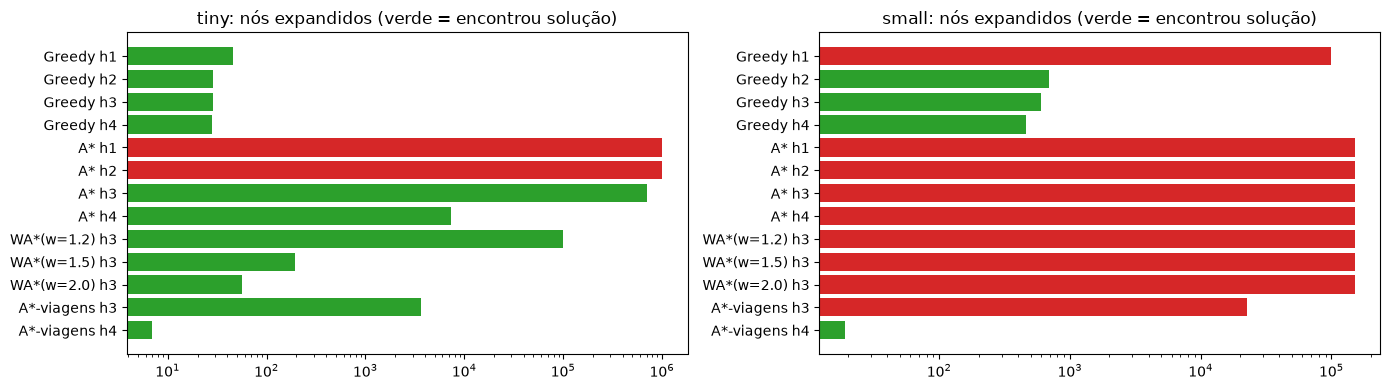

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, name in zip(axes, ("tiny", "small")):
    runs = informed[informed.dataset == name]
    labels = runs.algorithm + " " + runs.heuristic_name.str.split("_").str[0]
    ax.barh(labels, runs.expanded, color=["tab:green" if found else "tab:red" for found in runs.found])
    ax.set_xscale("log")
    ax.invert_yaxis()
    ax.set_title(f"{name}: nós expandidos (verde = encontrou solução)")
fig.tight_layout()

O A\* ponderado dá mais peso à heurística (f = g + w·h) para expandir menos nós, aceitando soluções até w vezes acima do ótimo. Curva no tiny, com h3.

      w      km  expandidos  segundos
0  1.30  533.09        6990     1.286
1  1.40  533.09         411     0.065
2  1.50  533.09         196     0.036
3  1.75  533.09          69     0.018
4  2.00  553.08          56     0.014
5  2.50  553.08          42     0.011
6  3.00  553.08          45     0.012


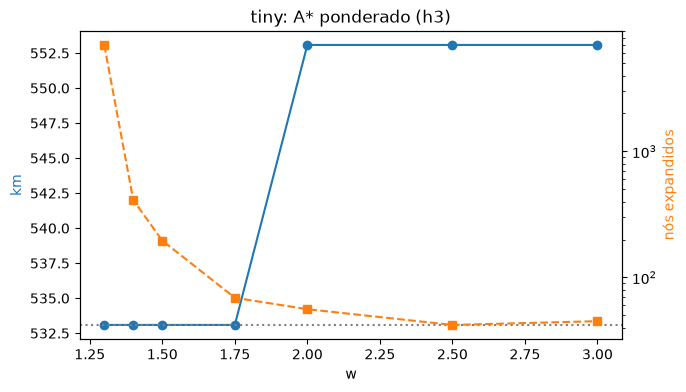

In [8]:
rows = []
for weight in (1.3, 1.4, 1.5, 1.75, 2.0, 2.5, 3.0):
    result = weighted_astar(tiny, h_mst, weight, max_expansions=100_000)
    rows.append(dict(w=weight, km=result.cost, expandidos=result.expanded, segundos=round(result.seconds, 3)))
weighted = pd.DataFrame(rows)
print(weighted)
fig, ax_km = plt.subplots(figsize=(7, 4))
ax_km.plot(weighted.w, weighted.km, "o-", color="tab:blue")
ax_km.axhline(optimal_km, color="grey", ls=":")
ax_km.set_ylabel("km", color="tab:blue")
ax_nodes = ax_km.twinx()
ax_nodes.plot(weighted.w, weighted.expandidos, "s--", color="tab:orange")
ax_nodes.set_yscale("log")
ax_nodes.set_ylabel("nós expandidos", color="tab:orange")
ax_km.set_xlabel("w")
ax_km.set_title("tiny: A* ponderado (h3)");

## 6. A\* por viagens

É o mesmo A\*, mas cada ação é uma viagem inteira. Há muito menos caminhos para a mesma solução, por isso a pesquisa fica muito mais pequena.

In [ ]:
rows = []
for name, problem in PROBLEMS.items():
    start = time.perf_counter()
    trip_catalog = TripCatalog(problem)
    rows.append(dict(dataset=name, ordens=trip_catalog.raw_orders, opcoes=len(trip_catalog.options),
                     catalogo_s=round(time.perf_counter() - start, 1)))
pd.DataFrame(rows)

In [10]:
# as duas formulações lado a lado
by_stop = informed[informed.algorithm == "A*"].assign(formulacao="paragem a paragem")
by_trip = informed[informed.algorithm == "A*-viagens"].assign(formulacao="viagem a viagem")
pd.concat([by_stop, by_trip]).pivot_table(index=["dataset", "heuristic_name"], columns="formulacao",
                                          values=["expanded", "cost_km", "seconds"], aggfunc="first")

cost_km                          expanded                           seconds                
formulacao             paragem a paragem viagem a viagem paragem a paragem viagem a viagem paragem a paragem viagem a viagem
dataset heuristic_name                                                                                                      
small   h1_max_detour                NaN             NaN          150000.0             NaN           104.120             NaN
        h2_min_arcs                  NaN             NaN          150000.0             NaN           122.855             NaN
        h3_mst                       NaN             NaN          150000.0         22530.0           141.623         600.059
        h4_relaxed                   NaN          757.84          150000.0            19.0            81.494           2.920
tiny    h1_max_detour                NaN             NaN         1000000.0             NaN           197.977             NaN
        h2_min_arcs                  NaN             NaN         1000000.0             NaN           218.486             NaN
        h3_mst                    533.09          533.09          709786.0          3681.0           167.704           5.592
        h4_relaxed                533.09          533.09            7302.0             7.0             0.991           0.011

## 7. Rotas do tiny

{'km': 533.09, 'feasible': True, 'trips': 6, 'late_min': 0.0, 'over_kg': 0.0, 'dwell_excess_min': 0.0, 'unserved': 0, 'deadlock': 0, 'overnight': 0, 'makespan_min': 2188.3, 'route_min': 922.5}
verificador: True
Veículo 1: W→P6→P4→P2→W | W→D1→D6→D7→D5→W
Veículo 2: W→P5→P3→P1→W | W→D11→D4→D10→D12→W | W→D2→D9→W | W→D8→D3→W


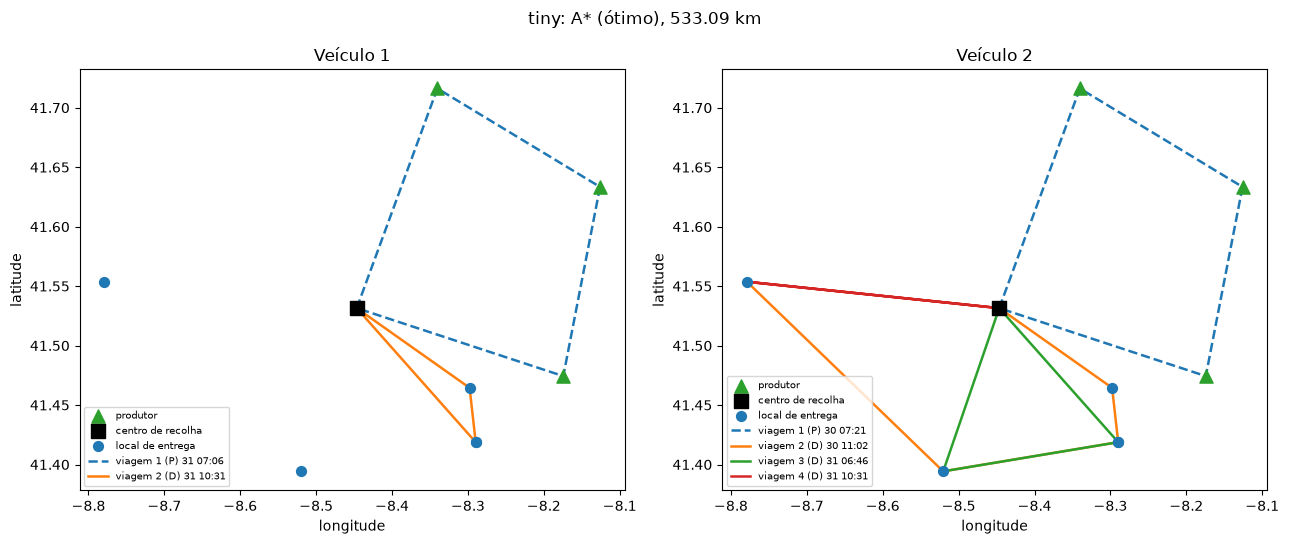

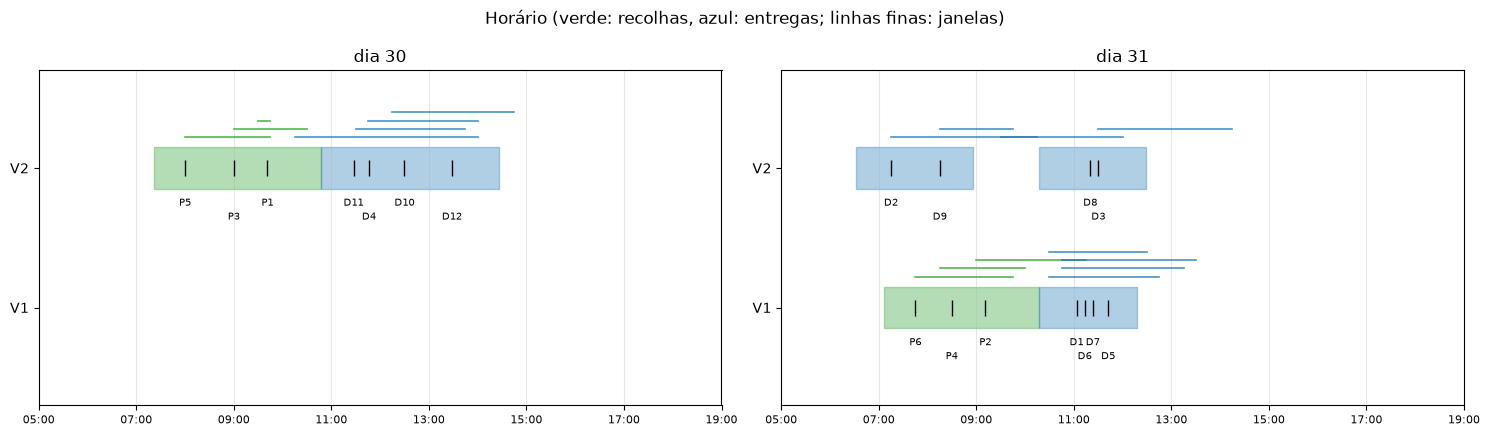

In [11]:
tiny_eval = evaluate(tiny, optimal_tiny)
print(tiny_eval.summary())
print("verificador:", check_solution(tiny, tiny_eval).valid)
print_routes(optimal_tiny)
plot_routes(tiny, optimal_tiny, f"tiny: A* (ótimo), {tiny_eval.km:.2f} km");
plot_gantt(tiny, tiny_eval);

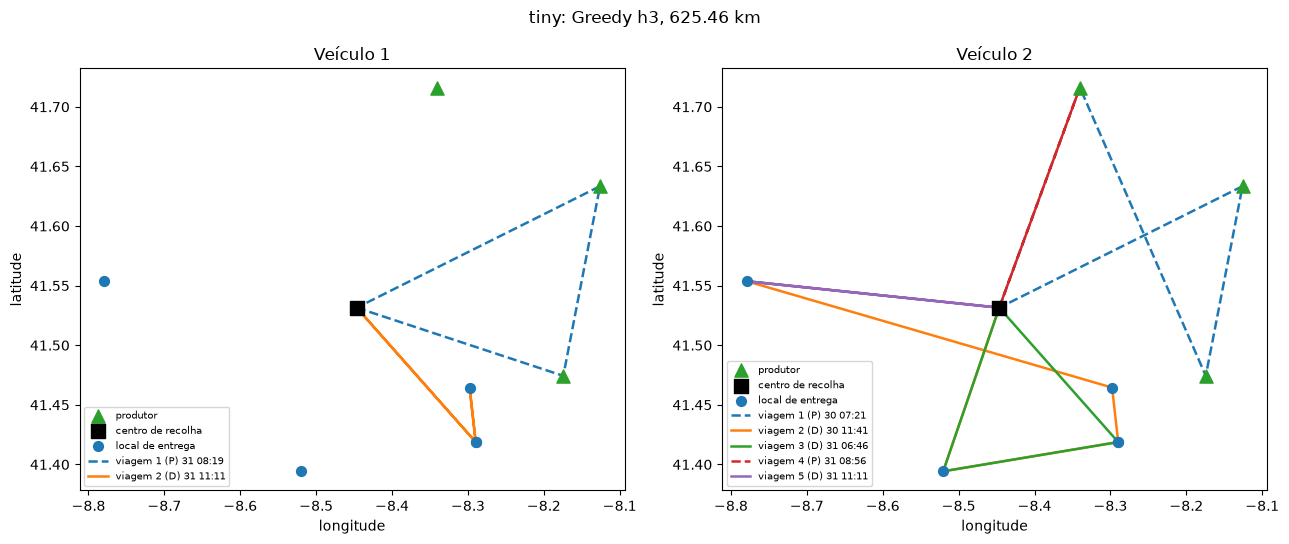

In [12]:
greedy_tiny = greedy(tiny, h_mst)
plot_routes(tiny, greedy_tiny.solution, f"tiny: Greedy h3, {greedy_tiny.cost:.2f} km");

## 8. Rotas do small

{'km': 757.84, 'feasible': True, 'trips': 6, 'late_min': 0.0, 'over_kg': 0.0, 'dwell_excess_min': 0.0, 'unserved': 0, 'deadlock': 0, 'overnight': 0, 'makespan_min': 2515.7, 'route_min': 1466.7}
verificador: True
Veículo 1: W→P9→W | W→D15→D16→D6→D18→D19→D1→D9→D2→W | W→D23→D5→D25→D14→D11→D17→W
Veículo 2: W→P7→P11→P1→P3→P5→W | W→P8→P12→P2→P4→P6→P10→W | W→D7→D21→D24→D10→D22→D13→D8→D12→D3→D20→D4→W


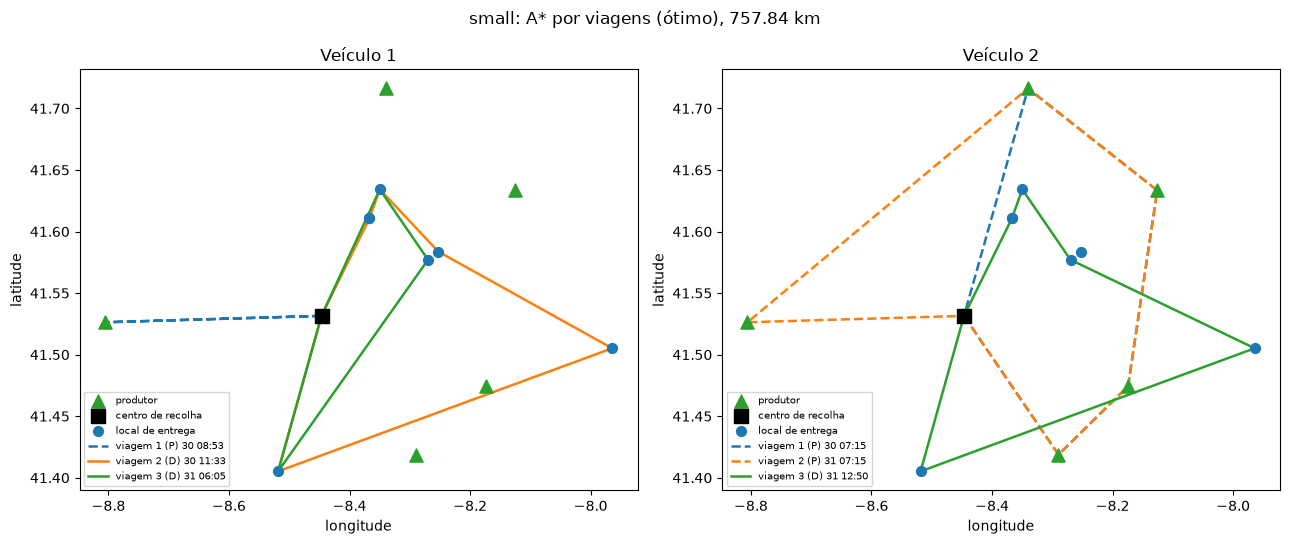

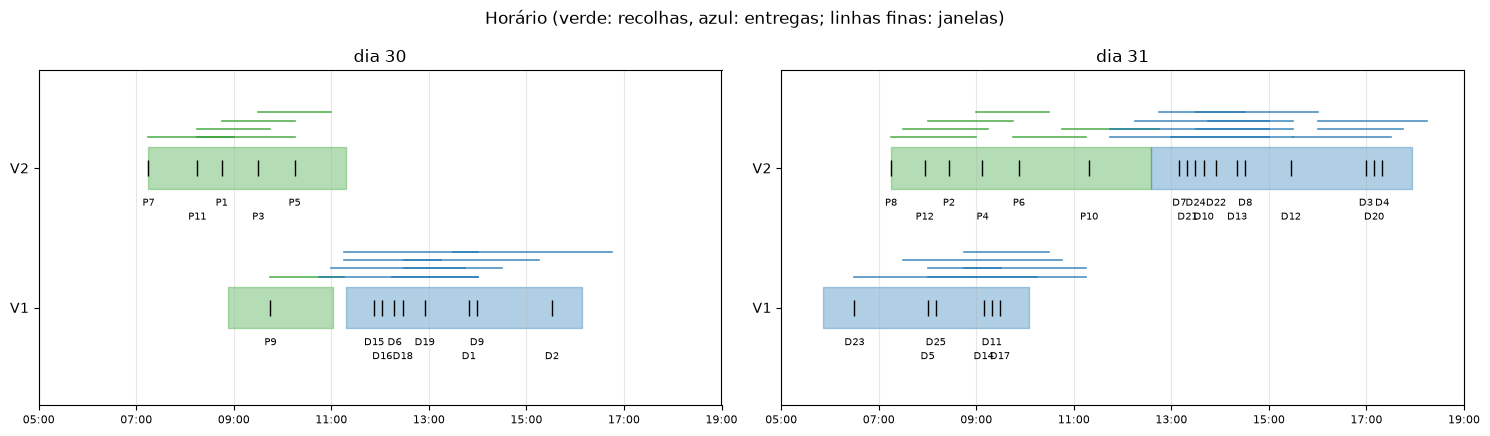

In [13]:
small_eval = evaluate(small, optimal_small)
print(small_eval.summary())
print("verificador:", check_solution(small, small_eval).valid)
print_routes(optimal_small)
plot_routes(small, optimal_small, f"small: A* por viagens (ótimo), {small_eval.km:.2f} km");
plot_gantt(small, small_eval);

## 9. Conclusões

- Com h1 e h2, o A\* esgota o orçamento sem solução.
- A h3 resolve o tiny com centenas de milhares de expansões; a h4 com milhares.
- Por viagens e com h4, o A\* prova o ótimo do tiny e do small com 7 e 19 expansões.
- O Greedy é instantâneo, mas fica 15–33% acima do ótimo no tiny.